# Exploring and Analyzing Paris trees data

Taken from https://s3-eu-west-1.amazonaws.com/static.oc-static.com/prod/courses/files/AI+Engineer/Project+2+Participez+%C3%A0+un+concours+sur+la+Smart+City/p2-arbres-fr.csv, coming from https://opendata.paris.fr/explore/dataset/les-arbres/map/?dataChart=eyJxdWVyaWVzIjpbeyJjb25maWciOnsiZGF0YXNldCI6Imxlcy1hcmJyZXMiLCJvcHRpb25zIjp7fX0sImNoYXJ0cyI6W3siYWxpZ25Nb250aCI6dHJ1ZSwidHlwZSI6ImNvbHVtbiIsImZ1bmMiOiJBVkciLCJ5QXhpcyI6ImlkYmFzZSIsInNjaWVudGlmaWNEaXNwbGF5Ijp0cnVlLCJjb2xvciI6IiMwMDMzNjYifV0sInhBeGlzIjoidHlwZWVtcGxhY2VtZW50IiwibWF4cG9pbnRzIjo1MCwic29ydCI6IiJ9XSwidGltZXNjYWxlIjoiIiwiZGlzcGxheUxlZ2VuZCI6dHJ1ZSwiYWxpZ25Nb250aCI6dHJ1ZX0%3D&disjunctive.typeemplacement&disjunctive.arrondissement&disjunctive.libellefrancais&disjunctive.genre&disjunctive.espece&disjunctive.varieteoucultivar&disjunctive.stadedeveloppement&disjunctive.remarquable&location=12,48.85984,2.31341&basemap=jawg.streets

## 1) Opening csv file

In [1]:
import pandas as pd
pd.set_option('display.float_format', '{:.2f}'.format) # don't want scientific notation. Floats are enough

csv_path = "./p2-trees-fr.csv"
df = pd.read_csv(csv_path, sep=';')

## 2) Naive Analysis

### Use pandas basic methods

In [2]:
import sys
print('Size in MB:')
sys.getsizeof(df)/(10**6)

Size in MB:


131.216112

In [3]:
df.info() # display count of columns, lines and columns names

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200137 entries, 0 to 200136
Data columns (total 18 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   id                   200137 non-null  int64  
 1   type_emplacement     200137 non-null  object 
 2   domanialite          200136 non-null  object 
 3   arrondissement       200137 non-null  object 
 4   complement_addresse  30902 non-null   object 
 5   numero               0 non-null       float64
 6   lieu                 200137 non-null  object 
 7   id_emplacement       200137 non-null  object 
 8   libelle_francais     198640 non-null  object 
 9   genre                200121 non-null  object 
 10  espece               198385 non-null  object 
 11  variete              36777 non-null   object 
 12  circonference_cm     200137 non-null  int64  
 13  hauteur_m            200137 non-null  int64  
 14  stade_developpement  132932 non-null  object 
 15  remarquable      

In [4]:
df.head(2) # display 2 first lines

,id,type_emplacement,domanialite,arrondissement,complement_addresse,numero,lieu,id_emplacement,libelle_francais,genre,espece,variete,circonference_cm,hauteur_m,stade_developpement,remarquable,geo_point_2d_a,geo_point_2d_b
0,99874,Arbre,Jardin,PARIS 7E ARRDT,NaN,NaN,MAIRIE DU 7E 116 RUE DE GRENELLE PARIS 7E,19,Marronnier,Aesculus,hippocastanum,NaN,20,5,NaN,0.00,48.86,2.32
1,99875,Arbre,Jardin,PARIS 7E ARRDT,NaN,NaN,MAIRIE DU 7E 116 RUE DE GRENELLE PARIS 7E,20,If,Taxus,baccata,NaN,65,8,A,NaN,48.86,2.32


In [5]:
df.describe()# general statistics only on number types variables (int and floats)

# problems:
## 0 as min value for circumference, height
## > 250000 cm as circumference, > 800000 m as height

,id,numero,circonference_cm,hauteur_m,remarquable,geo_point_2d_a,geo_point_2d_b
count,200137.00,0.00,200137.00,200137.00,137039.00,200137.00,200137.00
mean,387202.68,NaN,83.38,13.11,0.00,48.85,2.35
std,545603.24,NaN,673.19,1971.22,0.04,0.03,0.05
min,99874.00,NaN,0.00,0.00,0.00,48.74,2.21
25%,155927.00,NaN,30.00,5.00,0.00,48.84,2.31
50%,221078.00,NaN,70.00,8.00,0.00,48.85,2.35
75%,274102.00,NaN,115.00,12.00,0.00,48.88,2.39
max,2024745.00,NaN,250255.00,881818.00,1.00,48.91,2.47


In [6]:
# for column in df.columns[1:]:
    # df[column].value_counts()
# df.columns
# distribution discrète
for column in ['type_emplacement', 'domanialite', 'arrondissement',
       'lieu', 'id_emplacement', 'libelle_francais', 'genre', 'espece', 'variete',
       'hauteur_m', 'stade_developpement', 'remarquable', 'geo_point_2d_a',
       'geo_point_2d_b']:
    print(df[column].value_counts())
    print()
#     print(column + ':')
#     print(df[column].value_counts())
#     print()

type_emplacement
Arbre    200137
Name: count, dtype: int64

domanialite
Alignement      104949
Jardin           46262
CIMETIERE        31926
DASCO             6422
PERIPHERIQUE      5327
DJS               3900
DFPE              1325
DAC                 21
DASES                4
Name: count, dtype: int64

arrondissement
PARIS 15E ARRDT      17151
PARIS 13E ARRDT      16712
PARIS 16E ARRDT      16403
PARIS 20E ARRDT      15340
PARIS 19E ARRDT      13709
PARIS 12E ARRDT      12600
SEINE-SAINT-DENIS    11570
BOIS DE VINCENNES    11510
PARIS 14E ARRDT      11399
PARIS 17E ARRDT      10762
PARIS 18E ARRDT      10011
PARIS 7E ARRDT        8617
VAL-DE-MARNE          7580
PARIS 8E ARRDT        7245
PARIS 11E ARRDT       5658
HAUTS-DE-SEINE        5298
BOIS DE BOULOGNE      3978
PARIS 10E ARRDT       3385
PARIS 4E ARRDT        2740
PARIS 5E ARRDT        2368
PARIS 6E ARRDT        1764
PARIS 1ER ARRDT       1413
PARIS 3E ARRDT        1209
PARIS 9E ARRDT        1167
PARIS 2E ARRDT         548
Name

--> Statistic indicators seem to be coherent except max and min. When min == 0, is there 0 for other variables

### Looking for data anomalies

#### Nan values

In [7]:
df.columns # columns (type of data)

Index(['id', 'type_emplacement', 'domanialite', 'arrondissement',
       'complement_addresse', 'numero', 'lieu', 'id_emplacement',
       'libelle_francais', 'genre', 'espece', 'variete', 'circonference_cm',
       'hauteur_m', 'stade_developpement', 'remarquable', 'geo_point_2d_a',
       'geo_point_2d_b'],
      dtype='object')

In [8]:
import numpy as np

In [9]:
# number of 'nan' for each column
column_nb_of_nans = np.array([], dtype='int')
for column in df.columns:
    where_nan = df[df[column].isna()]
    column_nb_of_nans = np.concatenate((column_nb_of_nans,[len(where_nan)]))
column_nb_of_nans

array([     0,      0,      1,      0, 169235, 200137,      0,      0,
         1497,     16,   1752, 163360,      0,      0,  67205,  63098,
            0,      0])

In [10]:
# dataframe with number of nans per column only when one nan or more
where_nans = np.where(column_nb_of_nans>0)
columns_with_nans_df = pd.DataFrame([column_nb_of_nans[where_nans]], columns = df.columns[where_nans])
print('Number of nan for each variable that contains minimum 1 occurrence:')
columns_with_nans_df

Number of nan for each variable that contains minimum 1 occurrence:


,domanialite,complement_addresse,numero,libelle_francais,genre,espece,variete,stade_developpement,remarquable
0,1,169235,200137,1497,16,1752,163360,67205,63098


#### Other outliers (min and max)

##### Max

In [11]:
# based on the tallest tree height : https://en.wikipedia.org/wiki/Hyperion_(tree)
max_height = 116 # in meters
# based on the biggest tree girth (circumference) : https://www.guinnessworldrecords.com/world-records/living-tree-with-greatest-girth
max_girth = 36 # in meters

In [12]:
max_height_outlier_df = df[(df['hauteur_m'] > max_height)]
max_girth_outlier_df = df[(df['circonference_cm']/100 > max_girth)]

In [13]:
print('height outliers trees ('+ str(len(max_height_outlier_df)) + ' occurrencies):')
max_height_outlier_df


height outliers trees (87 occurrencies):


,id,type_emplacement,domanialite,arrondissement,complement_addresse,numero,lieu,id_emplacement,libelle_francais,genre,espece,variete,circonference_cm,hauteur_m,stade_developpement,remarquable,geo_point_2d_a,geo_point_2d_b
5392,106800,Arbre,Jardin,PARIS 7E ARRDT,NaN,NaN,JARDIN DU CHAMP DE MARS,A0120683,Tilleul,Tilia,n. sp.,NaN,100,1510,A,0.00,48.86,2.30
6473,107951,Arbre,Jardin,PARIS 7E ARRDT,NaN,NaN,JARDIN DU CHAMP DE MARS / C01 / ALLEE LEON BOU...,A00202003,Platane,Platanus,x hispanica,NaN,112,117,A,0.00,48.86,2.29
12536,115062,Arbre,Jardin,PARIS 16E ARRDT,11 à 27,NaN,JARDIN DE L AVENUE FOCH / 10 AVENUE FOCH,10303,Erable,Acer,n. sp.,NaN,47,255,J,0.00,48.87,2.29
15373,118412,Arbre,Jardin,PARIS 7E ARRDT,NaN,NaN,SQUARE DE L'ABBE ESQUERRE,17,Paulownia,Paulownia,tomentosa,NaN,145,810,A,0.00,48.85,2.31
24099,128185,Arbre,Jardin,PARIS 17E ARRDT,NaN,NaN,SQUARE ANDRE ULMANN,27,Platane,Platanus,x hispanica,NaN,130,125,A,0.00,48.89,2.30
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
187873,2008880,Arbre,DJS,PARIS 13E ARRDT,NaN,NaN,STADE CHARLETTY / 99 BOULEVARD KELLERMANN,91,Micocoulier,Celtis,australis,NaN,10,120,JA,0.00,48.82,2.35
187874,2008881,Arbre,DJS,PARIS 13E ARRDT,NaN,NaN,STADE CHARLETTY / 99 BOULEVARD KELLERMANN,92,Micocoulier,Celtis,australis,NaN,10,120,JA,0.00,48.82,2.35
189053,2011417,Arbre,Jardin,BOIS DE VINCENNES,NaN,NaN,PARC FLORAL DE PARIS / ROUTE DE LA PYRAMIDE,180088,Pin,Pinus,mugo,NaN,60,150,JA,0.00,48.83,2.44
189441,2011863,Arbre,DFPE,PARIS 16E ARRDT,NaN,NaN,ERLANGER (9-11) CRECHE,48970005,Marronnier,Aesculus,hippocastanum,Baumannii',8,157,NaN,0.00,48.85,2.26


In [14]:
max_height_outlier_df.value_counts('hauteur_m')

hauteur_m
120       7
155       5
118       5
125       4
810       4
117       3
205       3
1515      3
150       3
510       2
160       2
610       2
1510      2
1512      1
1511      1
5155      1
618       1
2525      1
714       1
720       1
2015      1
815       1
818       1
1815      1
1010      1
1113      1
1211      1
1216      1
1610      1
1514      1
615       1
260       1
608       1
159       1
122       1
128       1
129       1
130       1
138       1
148       1
154       1
156       1
157       1
170       1
512       1
180       1
190       1
204       1
216       1
218       1
219       1
220       1
255       1
327       1
881818    1
Name: count, dtype: int64

In [15]:
print('girth outliers trees ('+ str(len(max_girth_outlier_df)) + ' occurrencies):')
max_girth_outlier_df

girth outliers trees (20 occurrencies):


,id,type_emplacement,domanialite,arrondissement,complement_addresse,numero,lieu,id_emplacement,libelle_francais,genre,espece,variete,circonference_cm,hauteur_m,stade_developpement,remarquable,geo_point_2d_a,geo_point_2d_b
71787,190080,Arbre,DASCO,PARIS 20E ARRDT,NaN,NaN,PLAINE (9) ELEM B,11110006,Tilleul,Tilia,tomentosa,NaN,18589,15,A,0.00,48.85,2.40
82951,203295,Arbre,Alignement,PARIS 18E ARRDT,NaN,NaN,RUE D AUBERVILLIERS,301004,Erable,Acer,monspessulanum,NaN,5545,56,J,0.00,48.89,2.37
90605,211362,Arbre,Alignement,PARIS 5E ARRDT,34,NaN,BOULEVARD SAINT MARCEL,204025,Cedrele,Toona,sinensis,NaN,20130,16,A,0.00,48.84,2.36
91256,212024,Arbre,Alignement,PARIS 12E ARRDT,NaN,NaN,RUE DE CHALON,202005,Micocoulier,Celtis,australis,NaN,30140,10,A,0.00,48.85,2.37
97354,218274,Arbre,Alignement,PARIS 7E ARRDT,27,NaN,AVENUE RAPP,501003,Platane,Platanus,occidentalis,NaN,8110,18,A,0.00,48.86,2.30
103437,224609,Arbre,Alignement,PARIS 18E ARRDT,NaN,NaN,BOULEVARD BARBES,1303003,Platane,Platanus,x hispanica,NaN,9035,6,J,0.00,48.89,2.35
133546,256868,Arbre,Alignement,PARIS 19E ARRDT,NaN,NaN,AVENUE JEAN JAURES,1501006,Platane,Platanus,x hispanica,NaN,4090,10,A,0.00,48.89,2.39
147235,270997,Arbre,Alignement,PARIS 7E ARRDT,NaN,NaN,QUAI BRANLY,503005,Paulownia,Paulownia,tomentosa,NaN,9155,15,A,0.00,48.86,2.29
147634,271402,Arbre,Alignement,PARIS 7E ARRDT,NaN,NaN,AVENUE BOSQUET,1202016,Platane,Platanus,occidentalis,NaN,65110,16,A,0.00,48.86,2.31
148106,271884,Arbre,Alignement,PARIS 7E ARRDT,NaN,NaN,AVENUE BOSQUET,501022,Platane,Platanus,occidentalis,NaN,6595,15,A,0.00,48.86,2.30


In [16]:
max_girth_outlier_df.value_counts('circonference_cm')

circonference_cm
3630      1
4090      1
120170    1
79120     1
65110     1
30140     1
20130     1
18589     1
9155      1
9095      1
9085      1
9035      1
8110      1
7540      1
6595      1
6125      1
6120      1
6085      1
5545      1
250255    1
Name: count, dtype: int64

##### Min

In [17]:
# based on the tallest tree height : https://en.wikipedia.org/wiki/Hyperion_(tree)
min_height = 0 # in meters
# based on the biggest tree girth (circumference) : https://www.guinnessworldrecords.com/world-records/living-tree-with-greatest-girth
min_girth = 0 # in meters

In [18]:
min_height_outlier_df = df[(df['hauteur_m'] <= min_height)]
min_girth_outlier_df = df[(df['circonference_cm']/100 <= min_girth)]

In [19]:
print('height outliers trees ('+ str(len(min_height_outlier_df)) + ' occurrencies):')
min_height_outlier_df


height outliers trees (39219 occurrencies):


,id,type_emplacement,domanialite,arrondissement,complement_addresse,numero,lieu,id_emplacement,libelle_francais,genre,espece,variete,circonference_cm,hauteur_m,stade_developpement,remarquable,geo_point_2d_a,geo_point_2d_b
4,99878,Arbre,Jardin,PARIS 17E ARRDT,NaN,NaN,PARC CLICHY-BATIGNOLLES-MARTIN LUTHER KING,000G0037,Arbre à miel,Tetradium,daniellii,NaN,38,0,NaN,NaN,48.89,2.32
5,99879,Arbre,Jardin,PARIS 17E ARRDT,NaN,NaN,PARC CLICHY-BATIGNOLLES-MARTIN LUTHER KING,000G0036,Arbre à miel,Tetradium,daniellii,NaN,38,0,NaN,NaN,48.89,2.32
6,99880,Arbre,Jardin,PARIS 17E ARRDT,NaN,NaN,PARC CLICHY-BATIGNOLLES-MARTIN LUTHER KING,000G0035,Arbre à miel,Tetradium,daniellii,NaN,37,0,NaN,NaN,48.89,2.32
11,99885,Arbre,Jardin,PARIS 16E ARRDT,NaN,NaN,JARDIN DU RANELAGH,20001,Hêtre,Fagus,sylvatica,Atropunicea',30,0,NaN,NaN,48.86,2.27
12,99887,Arbre,Jardin,PARIS 16E ARRDT,NaN,NaN,JARDIN DU RANELAGH,20003,Micocoulier,Celtis,occidentalis,NaN,205,0,NaN,NaN,48.86,2.27
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200132,2024741,Arbre,Jardin,BOIS DE VINCENNES,NaN,NaN,ARBORETUM DE L ECOLE DU BREUIL - ROUTE DE LA F...,720170151,NaN,Castanea,fargesii,NaN,0,0,NaN,0.00,48.82,2.46
200133,2024742,Arbre,Jardin,BOIS DE VINCENNES,NaN,NaN,ARBORETUM DE L ECOLE DU BREUIL - ROUTE DE LA F...,720170152,Arbre aux mouchoirs,Davidia,involucrata,NaN,0,0,NaN,0.00,48.82,2.46
200134,2024743,Arbre,Jardin,BOIS DE VINCENNES,NaN,NaN,ARBORETUM DE L ECOLE DU BREUIL - ROUTE DE LA F...,720170153,Peuplier,Populus,simonii,NaN,0,0,NaN,0.00,48.82,2.46
200135,2024744,Arbre,Jardin,BOIS DE VINCENNES,NaN,NaN,ARBORETUM DE L ECOLE DU BREUIL - ROUTE DE LA F...,720170154,Chêne,Quercus,n. sp.,NaN,0,0,NaN,0.00,48.82,2.46


In [20]:
min_height_outlier_df.value_counts('hauteur_m')

hauteur_m
0    39219
Name: count, dtype: int64

In [21]:
print('girth outliers trees ('+ str(len(max_girth_outlier_df)) + ' occurrencies):')
min_girth_outlier_df

girth outliers trees (20 occurrencies):


,id,type_emplacement,domanialite,arrondissement,complement_addresse,numero,lieu,id_emplacement,libelle_francais,genre,espece,variete,circonference_cm,hauteur_m,stade_developpement,remarquable,geo_point_2d_a,geo_point_2d_b
1778,101922,Arbre,Jardin,PARIS 19E ARRDT,NaN,NaN,PARC DES BUTTES CHAUMONT,C0400032,Erable,Acer,platanoides,NaN,0,0,NaN,NaN,48.88,2.38
2332,102591,Arbre,Jardin,PARIS 17E ARRDT,NaN,NaN,PARC CLICHY-BATIGNOLLES-MARTIN LUTHER KING,000B0052,Magnolia,Magnolia,x soulangeana,Heaven Scent',0,0,NaN,NaN,48.89,2.32
2333,102592,Arbre,Jardin,PARIS 17E ARRDT,NaN,NaN,PARC CLICHY-BATIGNOLLES-MARTIN LUTHER KING,000B0053,Magnolia,Magnolia,x soulangeana,Heaven Scent',0,0,NaN,NaN,48.89,2.32
2405,102744,Arbre,Jardin,PARIS 20E ARRDT,NaN,NaN,SQUARE LEON FRAPIE,2,Platane,Platanus,x hispanica,NaN,0,0,JA,0.00,48.87,2.41
2430,102773,Arbre,Jardin,PARIS 17E ARRDT,NaN,NaN,PARC CLICHY-BATIGNOLLES-MARTIN LUTHER KING,000B0021,Magnolia,Magnolia,x soulangeana,Sundew',0,0,NaN,NaN,48.89,2.32
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200132,2024741,Arbre,Jardin,BOIS DE VINCENNES,NaN,NaN,ARBORETUM DE L ECOLE DU BREUIL - ROUTE DE LA F...,720170151,NaN,Castanea,fargesii,NaN,0,0,NaN,0.00,48.82,2.46
200133,2024742,Arbre,Jardin,BOIS DE VINCENNES,NaN,NaN,ARBORETUM DE L ECOLE DU BREUIL - ROUTE DE LA F...,720170152,Arbre aux mouchoirs,Davidia,involucrata,NaN,0,0,NaN,0.00,48.82,2.46
200134,2024743,Arbre,Jardin,BOIS DE VINCENNES,NaN,NaN,ARBORETUM DE L ECOLE DU BREUIL - ROUTE DE LA F...,720170153,Peuplier,Populus,simonii,NaN,0,0,NaN,0.00,48.82,2.46
200135,2024744,Arbre,Jardin,BOIS DE VINCENNES,NaN,NaN,ARBORETUM DE L ECOLE DU BREUIL - ROUTE DE LA F...,720170154,Chêne,Quercus,n. sp.,NaN,0,0,NaN,0.00,48.82,2.46


In [22]:
min_girth_outlier_df.value_counts('circonference_cm')

circonference_cm
0    25867
Name: count, dtype: int64

# 3) Detailed univariate analysis of each variable

In [23]:
# def variable_univariate_analysis(df, variable_name, variable_type, variable_title_type=None):
#     import numpy as np
#     import seaborn as sns
#     import matplotlib.pyplot as plt

#     if variable_title_type == None:
#         variable_title_type = variable_type
    
#     # variable_type can four types
#     variable_types = ['qualitative_nominal','qualitative_ordinal','quantitative_discrete','quantitative_continuous']
#     variable_type = str.lower(variable_type)
#     if variable_type not in variable_types:
#         print('Error : wrong variable_type')
#     else:
#         # bars but can also be pie
#         if variable_type=='qualitative_nominal':
#             value_counts = df[variable_name].value_counts(normalize=True)
#             max_values = 26
#             if len(value_counts) >= 26:
#                 top_values = value_counts[0:max_values]
#                 others = value_counts[max_values:].sum()
#                 if variable_title_type == variable_type:
#                     others_label = 'others'
#                 else:
#                     others_label = '> ' + str(max_values)
#                 top_values[others_label] = others
#                 value_counts = top_values
#             value_counts.plot(kind='bar')
#         elif variable_type == 'qualitative_ordinal': 
#             df.sort_values(by=variable_name, ascending=True, inplace=True)
#             variable_univariate_analysis(df, variable_name, 'qualitative_nominal', variable_type)
#             pass
#         elif variable_type == 'quantitative_discrete':
#             df.sort_values(by=variable_name, ascending=True, inplace=True)
#             value_counts = df[variable_name].value_counts(normalize=True)
#             value_counts.plot(kind='bar')
#             pass
#         elif variable_type == 'quantitative_continuous':
#             sns.histplot(df[variable_name][df[variable_name] <= df[variable].quantile(0.99)], stat='frequency', kde=True)
#             pass

#         if variable_type != 'qualitative_ordinal':
#             plt.title(variable_name + ' ( ' + variable_title_type + ' )')
#         plt.show()

In [24]:
# import numpy as np
# import seaborn as sns
# import matplotlib.pyplot as plt
# import pandas as pd

# def plot_variable_distribution(df: pd.DataFrame, variable_name: str, variable_type: str, variable_title_type: str = None) -> None:
#     """
#     Plots the distribution of a variable based on its type.

#     Args:
#         df (pd.DataFrame): The DataFrame containing the data.
#         variable_name (str): The name of the variable to plot.
#         variable_type (str): The type of the variable (e.g., 'qualitative_nominal', 'qualitative_ordinal', 
#                              'quantitative_discrete', 'quantitative_continuous').
#         variable_title_type (str, optional): An optional title type for the variable. Defaults to None.

#     Raises:
#         ValueError: If the variable_type is not recognized.
#     """
#     if variable_title_type is None:
#         variable_title_type = variable_type

#     variable_types = ['qualitative_nominal', 'qualitative_ordinal', 'quantitative_discrete', 'quantitative_continuous']
#     variable_type = variable_type.lower()

#     if variable_type not in variable_types:
#         raise ValueError('Error: wrong variable_type')

#     if variable_type == 'qualitative_nominal':
#         value_counts = df[variable_name].value_counts(normalize=True)
#         max_values = 26
#         if len(value_counts) >= max_values:
#             top_values = value_counts.head(max_values)
#             others = value_counts.iloc[max_values:].sum()
#             others_label = 'others' if variable_title_type == variable_type else f'> {max_values}'
#             top_values[others_label] = others
#             value_counts = top_values
#         value_counts.plot(kind='bar')

#     elif variable_type == 'qualitative_ordinal':
#         df.sort_values(by=variable_name, ascending=True, inplace=True)
#         plot_variable_distribution(df, variable_name, 'qualitative_nominal', variable_type)

#     elif variable_type == 'quantitative_discrete':
#         df.sort_values(by=variable_name, ascending=True, inplace=True)
#         value_counts = df[variable_name].value_counts(normalize=True)
#         value_counts.plot(kind='bar')

#     elif variable_type == 'quantitative_continuous':
#         sns.histplot(df[variable_name][df[variable_name] <= df[variable_name].quantile(0.99)], stat='frequency', kde=True)

#     if variable_type != 'qualitative_ordinal':
#         plt.title(f"{variable_name} ({variable_title_type})")
#     plt.show()

In [111]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import folium
from folium.plugins import MarkerCluster
import branca
from IPython.display import display
from scipy.spatial import cKDTree
from geopy.distance import geodesic


def plot_variable_distribution(
    df: pd.DataFrame, 
    variable_name: str, 
    graph_type: str, 
    variable_title_type: str = None,
) -> None:
    """
    Plots the distribution of a specified variable in a DataFrame based on the graph type.

    Args:
        df (pd.DataFrame): The DataFrame containing the data.
        variable_name (str): The name of the variable to plot.
        graph_type (str): The type of graph to plot (e.g., 'pie', 'heat_map', 'bars', 'hist', 'bars_log').
        variable_title_type (str, optional): An optional title type for the variable. Defaults to None.

    Raises:
        ValueError: If the graph_type is not recognized or if latitude/longitude columns are missing.
    """
    if variable_title_type is None:
        variable_title_type = graph_type

    graph_types = ['pie', 'heat_map', 'bars', 'hist', 'bars_log', 'boxplot']
    graph_type = graph_type.lower()

    if graph_type not in graph_types:
        raise ValueError('Error: wrong graph_type')

    if graph_type == 'pie':
        value_counts = df[variable_name].value_counts(normalize=True)
        value_counts_percent = value_counts * 100  # Convert to percentage

        # Group classes with less than 2% into "Others"
        others_count = value_counts_percent[value_counts_percent < 2]
        if not others_count.empty:
            others_label = f"Others ({', '.join(others_count.index)})"
            value_counts = value_counts_percent[value_counts_percent >= 2]
            value_counts[others_label] = others_count.sum()  # Add the "Others" category

        plt.pie(
            value_counts, 
            labels=[f"{label} ({count:.1f}%)" for label, count in zip(value_counts.index, value_counts.values)],
            autopct='%1.1f%%'
        )
        plt.title(f"{variable_name} Distribution")

    elif graph_type == 'heat_map':
        # Check if the DataFrame contains the necessary geographic columns
        if 'geo_point_2d_a' in df.columns and 'geo_point_2d_b' in df.columns and variable_name in df.columns:
            # Group by the variable of interest (e.g., 'city', 'region') and count the occurrences in each sector
            sector_data = df.groupby([variable_name]).agg({
                'geo_point_2d_a': 'mean',
                'geo_point_2d_b': 'mean',
            }).reset_index()
    
            # Add a "population density" column based on the number of occurrences of the variable in each sector
            sector_data['counts'] = df.groupby(variable_name).size().values

            # Calculate the occurrence percentages
            total_counts = sector_data['counts'].sum()
            sector_data['percentage'] = (sector_data['counts'] / total_counts) * 100

            # Common zoom level used for city-level maps in Folium (and Leaflet)
            zoom_level = 12
            # Create a map centered around the average geographic points
            m = folium.Map(location=[sector_data['geo_point_2d_a'].mean(), sector_data['geo_point_2d_b'].mean()], zoom_start=zoom_level)
    
            # Normalize population densities for the heat map
            min_density = sector_data['counts'].min()
            max_density = sector_data['counts'].max()
    
            # Create the colormap with branca
            colormap = branca.colormap.LinearColormap(
                colors=['yellow', 'orange', 'red'],  # Choose a classic heatmap palette (yellow-orange-red)
                vmin=min_density, vmax=max_density
            ).to_step(10)  # Divide the colormap into 10 steps for the legend

            # Extract coordinates of the sectors
            coords = sector_data[['geo_point_2d_a', 'geo_point_2d_b']].values
            tree = cKDTree(coords)  # Create the k-d tree with the coordinates

            # Initialize the minimum distance to a very large number
            min_distance = float('inf')
            closest_pair = None

            # Find the closest pairs
            for i, point in enumerate(coords):
                # Find the closest neighbor from point i (excluding the point itself)
                distances, indices = tree.query(point, k=2)  # k=2 to get the closest neighbor and itself
                
                # The second closest will be the nearest (the first is the point itself)
                closest_distance = distances[1]
                closest_index = indices[1]
                
                # If the found distance is smaller, update the minimum distance and associated points
                if closest_distance < min_distance:
                    min_distance = closest_distance
                    closest_pair = (point, coords[closest_index])

            # Convert the minimum Euclidean distance to geodesic distance for more accuracy
            min_distance = geodesic(closest_pair[0], closest_pair[1]).meters

            # Limit the circle size to half the smallest distance between two points
            max_circle_radius = min_distance / 2
            
            # Average Earth radius in meters
            EARTH_RADIUS = 6371000
    
            # Calculate the size of a pixel in meters (at the given average latitude)
            lat_rad = np.radians(np.mean(sector_data['geo_point_2d_b']))
            meters_per_pixel = (2 * np.pi * EARTH_RADIUS) / (256 * (2 ** zoom_level)) * np.cos(lat_rad)
    
            max_circle_radius_in_pixels = max_circle_radius / meters_per_pixel
    
            # Add each sector as a colored circle based on population density
            for _, row in sector_data.iterrows():
                color = colormap(row['counts'])  # Use the colormap to get the color based on density
    
                # Calculate the size of the marker based on density
                # size = np.log(row['population_density'] + 1) * 5  # Logarithmic for a reasonable scale
                # size = max(10, min(size, max_circle_radius))  # Limit the size to max_circle_radius
                size = max_circle_radius_in_pixels
    
                # Add a circle to the map
                folium.CircleMarker(
                    location=[row['geo_point_2d_a'], row['geo_point_2d_b']],
                    radius=size,  # Circle size based on density and minimum distance
                    color=color,
                    fill=True,
                    fill_color=color,  # Fill with the same color
                    fill_opacity=0.7,
                    popup=f"{variable_name}: {row[variable_name]}<br>Trees: {row['counts']}<br>Percentage: {row['percentage']:.3}%",
                    # Allow the size to adjust based on zoom level
                    zoom_on_click=True
                ).add_to(m)

            # Add the colormap legend to the map
            colormap.caption = f"Trees per {variable_name}"
            colormap.add_to(m)
            
            # Force the legend to the bottom left corner using CSS style
            m.get_root().html.add_child(folium.Element("""
                <style>
                    .leaflet-control-colormap { 
                        position: absolute !important; 
                        bottom: 10px; 
                        left: 10px; 
                        z-index: 1000;
                    }
                </style>
            """))
    
            # Display the map
            display(m)
            m.save(f'./map_{variable_name}.html')
            return  # End the function
    
        else:
            raise ValueError("The DataFrame must contain 'geo_point_2d_a', 'geo_point_2d_b', and the sector variable to display a map.")

    elif graph_type in ['bars', 'bars_log']:
        value_counts = df[variable_name].value_counts()

        # Group smaller classes into "others" if there are more than 26
        if len(value_counts) > 26:
            top_categories = value_counts[:25]
            others_count = value_counts[25:].sum()
            value_counts = pd.concat([top_categories, pd.Series({'others': others_count})])

        total = value_counts.sum()
        plt.figure(figsize=(10, 6))
        ax = sns.barplot(x=value_counts.index, y=value_counts.values)
        plt.title(f"{variable_name} Distribution")
        
        # Add percentages inside the bars
        for p, percentage in zip(ax.patches, value_counts / total * 100):
            rotation = 90 if len(value_counts) > 10 else 0
            ax.annotate(
                f"{percentage:.1f}%",
                (p.get_x() + p.get_width() * 0.50, p.get_height() * 0.90),
                ha='center', va='center', fontsize=10, rotation=rotation, color='black'
            )
        
        plt.xlabel(variable_name)
        plt.ylabel('Count')
        if graph_type == 'bars_log':
            plt.yscale('log')
        plt.xticks(rotation=90 if len(value_counts) > 10 else 0)  # Rotate labels if too many
        plt.show()

    elif graph_type == 'hist':
        plt.figure(figsize=(10, 6))
        sns.histplot(df[variable_name][df[variable_name] <= df[variable].quantile(0.99)], kde=True)
        # sns.histplot(df[variable_name], kde=True, color='blue', bins=15)
        plt.title(f"{variable_name} Distribution")
        plt.xlabel(variable_name)
        plt.ylabel('Count')
        plt.show()

    elif graph_type == "boxplot":
        sns.boxplot(y=df[variable_name][df[variable_name] <= df[variable].quantile(0.99)])
        plt.title(f"{variable_name} Distribution (Boxplot)")
        plt.ylabel(variable_name)
        plt.show()
        


In [29]:
df.columns

Index(['id', 'type_emplacement', 'domanialite', 'arrondissement',
       'complement_addresse', 'numero', 'lieu', 'id_emplacement',
       'libelle_francais', 'genre', 'espece', 'variete', 'circonference_cm',
       'hauteur_m', 'stade_developpement', 'remarquable', 'geo_point_2d_a',
       'geo_point_2d_b'],
      dtype='object')

In [30]:
df['id_emplacement'].unique()
df.value_counts('id_emplacement')

id_emplacement
101001      1324
101002      1241
101003      1128
202001      1032
101004      1020
            ... 
80269          1
80270          1
80271          1
80272          1
Q9630006       1
Name: count, Length: 69040, dtype: int64

In [31]:
df.value_counts('lieu')

lieu
PARC FLORAL DE PARIS / ROUTE DE LA PYRAMIDE                       2995
PARC DES BUTTES CHAUMONT                                          2331
PARC ANDRE CITROEN                                                2095
PARC OMNISPORT SUZANNE LENGLEN / 7 BOULEVARD DES FRERES VOISIN    1478
INSEP / AVENUE DU TREMBLAY                                        1293
                                                                  ... 
CIMETIERE DU PERE LACHAISE / AVENUE DES THUYAS / DIV 80              1
CIMETIERE DE SAINT-OUEN ANCIEN / DIV 10                              1
CIMETIERE DE SAINT-OUEN ANCIEN / DIV 4                               1
CARREFOUR ODEON                                                      1
POMMARD (33) MAT                                                     1
Name: count, Length: 6921, dtype: int64

In [32]:
df.columns

Index(['id', 'type_emplacement', 'domanialite', 'arrondissement',
       'complement_addresse', 'numero', 'lieu', 'id_emplacement',
       'libelle_francais', 'genre', 'espece', 'variete', 'circonference_cm',
       'hauteur_m', 'stade_developpement', 'remarquable', 'geo_point_2d_a',
       'geo_point_2d_b'],
      dtype='object')

In [33]:
df.value_counts('variete')

variete
Baumannii'            4538
Briotii'              2827
Euchlora'             2756
Chanticleer'          2595
Fastigiata'           2483
                      ... 
Précoce de Saumur'       1
Profusion'               1
Porlock'                 1
Hilsop'                  1
Neapolitanum'            1
Name: count, Length: 436, dtype: int64

In [34]:
# interesting_variables = {'domanialite':'qualitative_nominal','arrondissement':'qualitative_nominal',
#                         'lieu':'qualitative_nominal', 'libelle_francais':'qualitative_nominal',
#                         'genre':'qualitative_nominal', 'espece':'qualitative_nominal',
#                         'variete':'qualitative_nominal','circonference_cm':'quantitative_continuous',
#                         'hauteur_m':'quantitative_continuous','stade_developpement':'qualitative_ordinal',
#                          'remarquable':'qualitative_ordinal'}

In [35]:
interesting_variables = {'domanialite':'pie','arrondissement':'heat_map',
                        'lieu':'heat_map', 'libelle_francais':'bars',
                        'genre':'bars', 'espece':'bars',
                        'variete':'bars','circonference_cm':'hist',
                        'hauteur_m':'hist','stade_developpement':'pie',
                         'remarquable':'bars_log'}

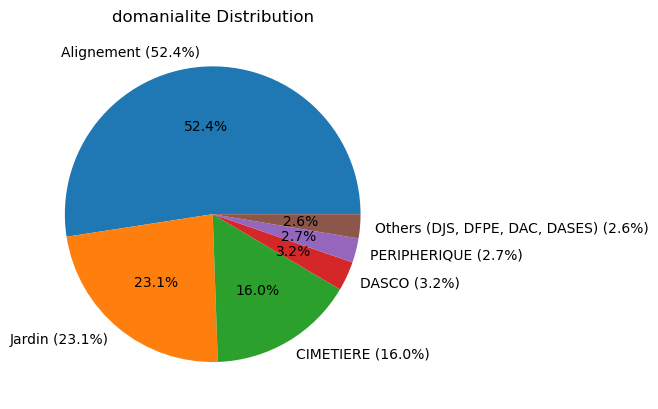

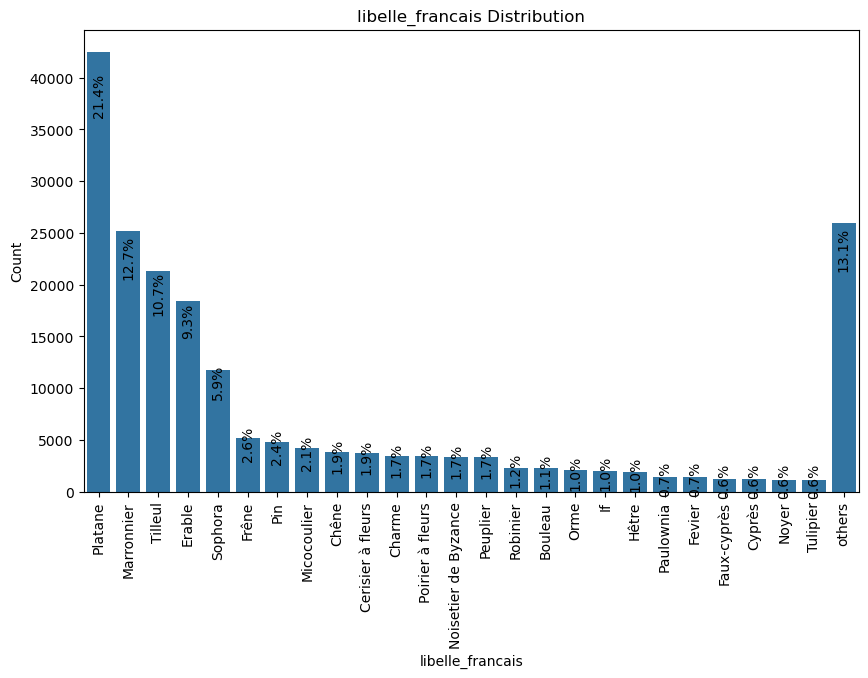

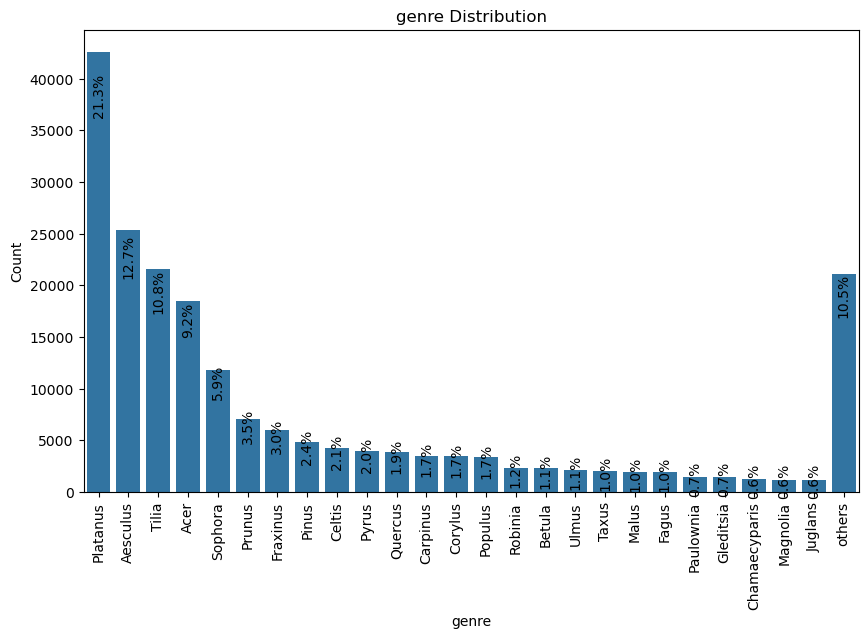

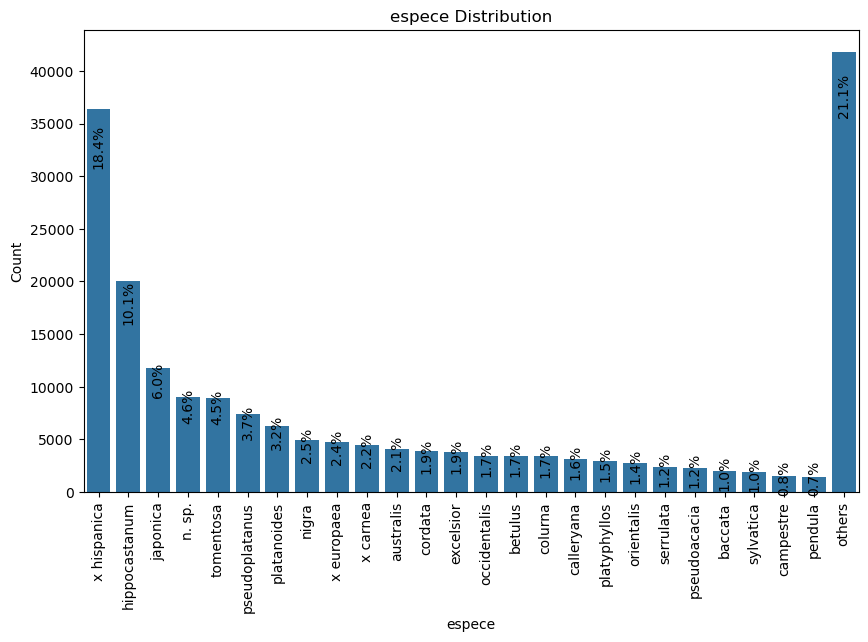

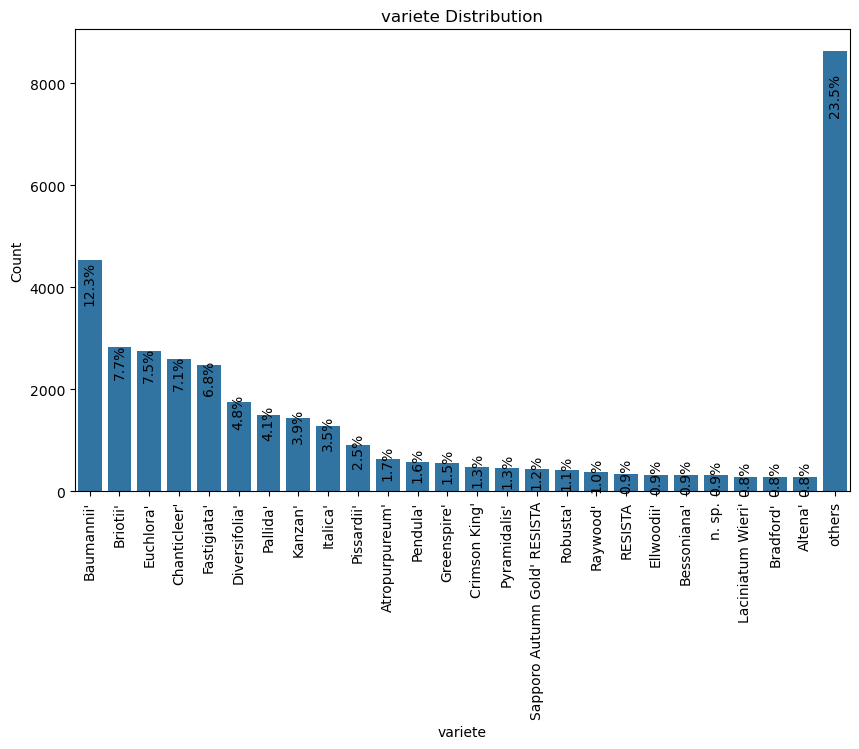

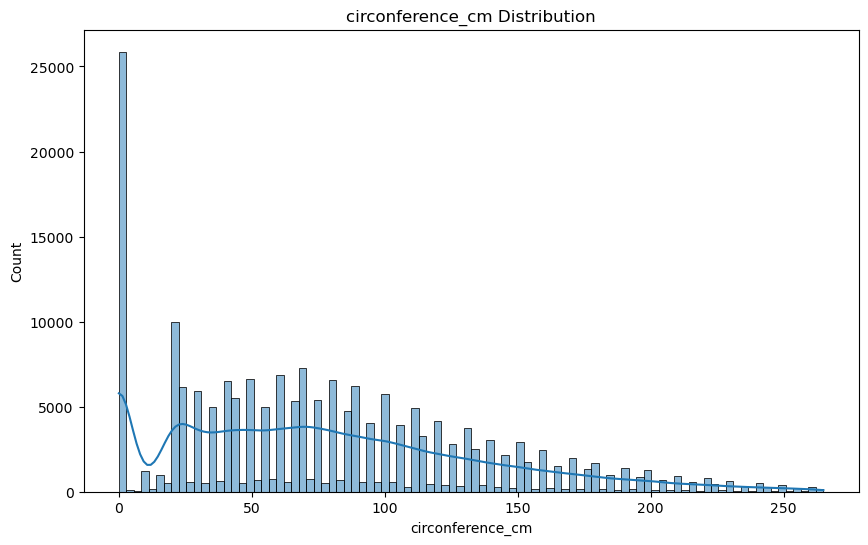

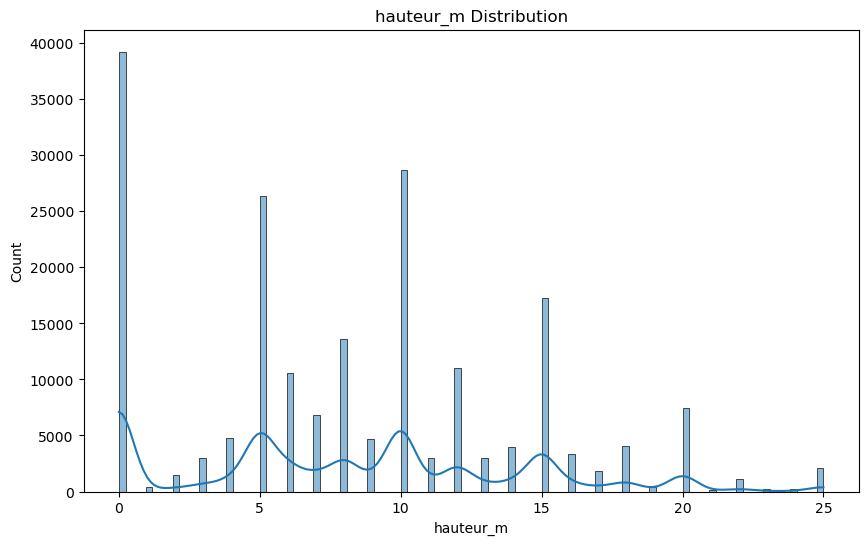

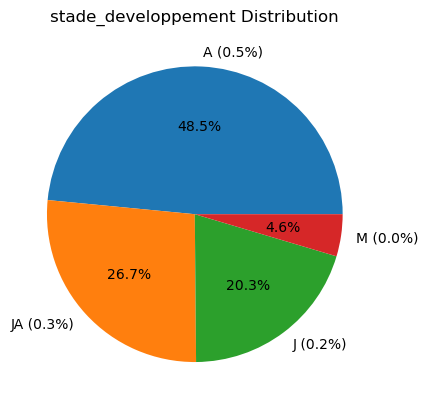

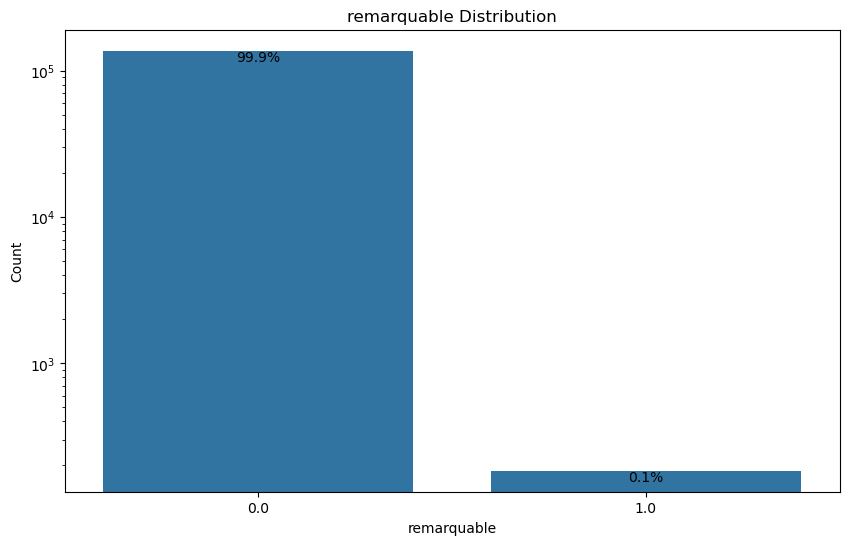

In [83]:
for variable in interesting_variables:
    plot_variable_distribution(df, variable, interesting_variables[variable])

In [ ]:
interesting_variables

In [ ]:
variable = 'hauteur_m'
# variable_univariate_analysis(df, variable, interesting_variables[variable])
import seaborn as sns
import matplotlib.pyplot as plt
# %matplotlib widget
# ax = sns.histplot(df[variable], bins=20, kde=True)
filtered_data = df[variable][df[variable]<=40]
# sns.histplot(df[variable][df[variable] <= df[variable].quantile(0.99)], stat='frequency', binwidth = 1, binrange=(0,20), kde=True)
sns.histplot(df[variable][df[variable] <= df[variable].quantile(0.99)], stat='frequency', kde=True)
# plt.show()

In [ ]:
variable = 'domanialite'
variable_univariate_analysis(df, variable, interesting_variables[variable])

In [112]:
interesting_variables = {'circonference_cm':'boxplot',
                        'hauteur_m':'boxplot'}

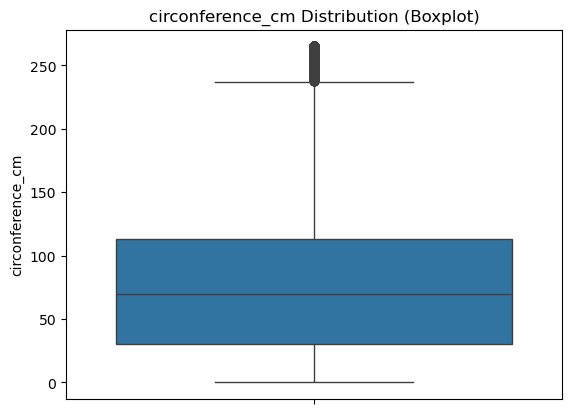

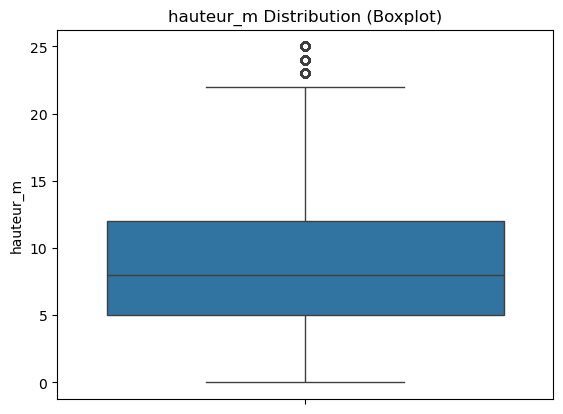

In [113]:
for variable in interesting_variables:
    plot_variable_distribution(df, variable, interesting_variables[variable])

# 3

In [ ]:
# genre and libelle_francais, espece etc. : search for same trees with more metadata : step 4

In [ ]:
# regarder si les arbres avec hauteur et circonférence nulle se rencontrent ou pas. Graines plantées ? 
# Relevés non faits (pourquoi on donnerait une position, alors?)

In [ ]:
## 4 : traitement valeurs aberrantes
# report this tree to Paris City : the owner is unknown --> look for similar trees in order to find the right owner : step 4
df[df['domanialite'].isna()]

In [ ]:
import folium
import missingno

In [ ]:
# pistes amélioration : proposer trajet pour arbres de plus de x mètres (nacelle)
# regarder sur carte à quoi correspondent les id d'emplacements, par rapport aux lieux